[*********************100%***********************]  2 of 2 completed

Fetching KO and PEP data...


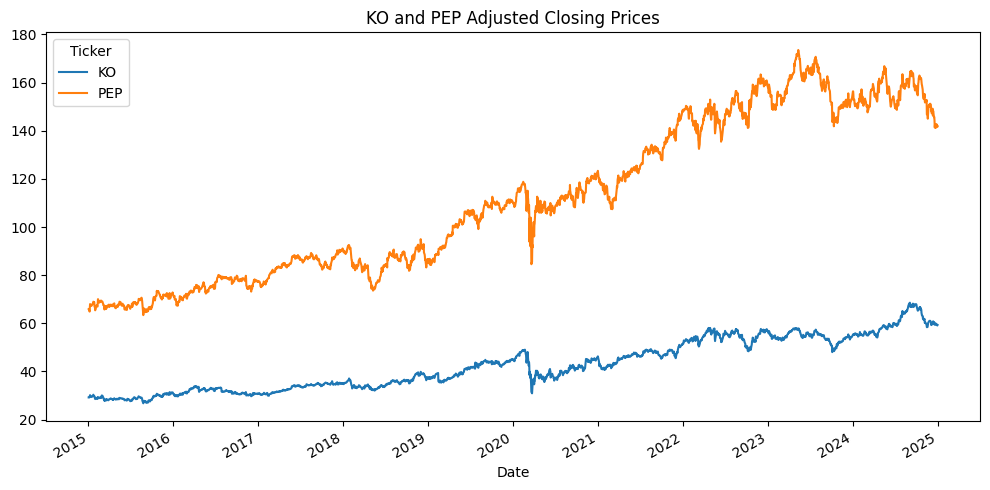

Cointegration statistic: -3.5764
Cointegration p-value: 0.0262


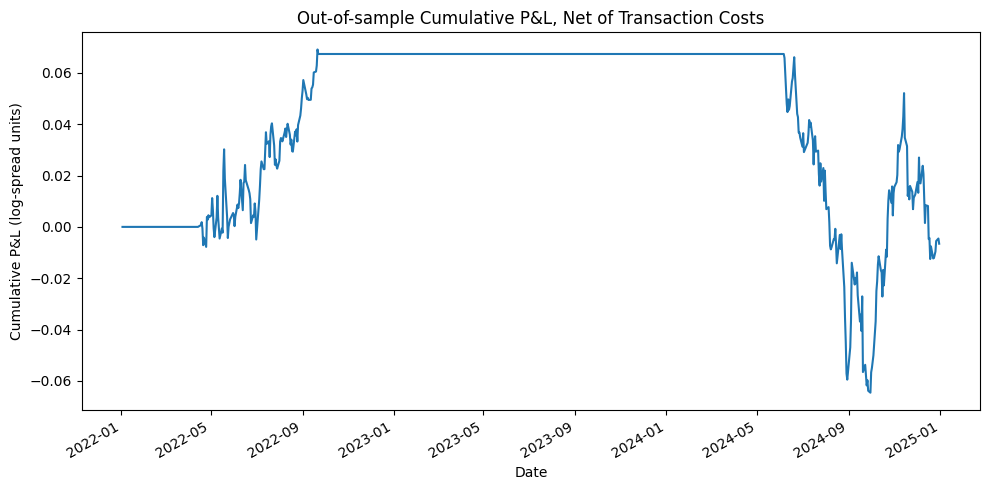


--- Backtest Execution Complete ---
Total Cumulative P&L Units: -0.0066
Max Drawdown Units:        -0.1338
Position Changes (entries + exits):     3


In [4]:
!pip install yfinance
import yfinance as yf
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint

def main():
    # fetching data from yfinance
    print("Fetching KO and PEP data...")
    prices = yf.download(["KO", "PEP"], start="2015-01-01", end="2025-01-01", auto_adjust=True)["Close"].dropna()

    # save price plots
    fig, ax = plt.subplots(figsize = (10, 5))
    prices.plot(ax = ax, title = "KO and PEP Adjusted Closing Prices")
    plt.tight_layout()
    plt.savefig("prices.png")
    plt.show()
    plt.close()

    # log transformation of prices and splitting test/ training data
    logp = np.log(prices)
    train = logp.loc[:"2021-12-31"]
    test = logp.loc["2022-01-01":]

    # cointegration testing
    t_stat, p_value, _ = coint(train["KO"], train["PEP"])
    print(f"Cointegration statistic: {t_stat:.4f}")
    print(f"Cointegration p-value: {p_value:.4f}")

    # long-run relationship (OLS regression)
    X = sm.add_constant(train["PEP"])
    model = sm.OLS(train["KO"], X).fit()
    alpha, beta = model.params["const"], model.params["PEP"]

    # calculating spread
    spread_func = lambda df: df["KO"] - alpha - (beta * df["PEP"])

    train_spread = spread_func(train)
    mu, sigma = train_spread.mean(), train_spread.std()

    test_spread = spread_func(test)
    z = (test_spread - mu) / sigma

    # save training spread plot
    plt.figure(figsize=(10, 4))
    train_spread.plot(title="KO-PEP Log-Price Spread: Training Period")
    plt.axhline(mu, color="black", linestyle="--", label="Mean")
    plt.axhline(mu + 2 * sigma, color="red", linestyle=":", label="+2 SD")
    plt.axhline(mu - 2 * sigma, color="green", linestyle=":", label="-2 SD")
    plt.legend()
    plt.tight_layout()
    plt.savefig("training_spread.png")
    plt.close()

    # generating trading positions
    pos = pd.Series(0.0, index=z.index)
    current = 0
    for t in range(len(z)):
        z_val = z.iloc[t]
        if current == 0:
            current = -1 if z_val > 2 else (1 if z_val < -2 else 0)     # short spread when z>2 and long when z<-2
        elif current == 1 and z_val > -0.5:
            current = 0
        elif current == -1 and z_val < 0.5:
            current = 0
        pos.iloc[t] = current

    # position earns the next day's spread change (signal at close t, held t to t + 1), avoiding look-ahead bias
    pos = pos.shift(1).fillna(0)


    # test-period z-score and positions
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1]})
    ax1.plot(z, label="Spread z-score", color="tab:blue")
    ax1.axhline(2, color="red", linestyle=":", label="Short threshold (+2)")
    ax1.axhline(-2, color="green", linestyle=":", label="Long threshold (-2)")
    ax1.axhline(0.5, color="orange", linestyle=":", label="Exit thresholds (±0.5)")
    ax1.axhline(-0.5, color="orange", linestyle=":")
    ax1.axhline(0, color="black", linestyle="--")
    ax1.set_title("Trading Signal and Position: Test Period")
    ax1.legend(loc="upper left")

    ax2.step(pos.index, pos, where="post", color="black")
    ax2.set_yticks([-1, 0, 1])
    ax2.set_yticklabels(["Short", "Flat", "Long"])
    ax2.set_ylim(-1.2, 1.2)
    plt.tight_layout()
    plt.savefig("signals.png")
    plt.close()

    spread_ret = test_spread.diff()
    trades = pos.diff().abs().fillna(0)
    cost = 0.0010  * (1 + abs(beta)) # 10 bps per leg; the spread trades KO and beta x PEP
    pnl = (pos * spread_ret) - (trades * cost) # estimating daily profit/ loss from the changes in spread
    equity = pnl.fillna(0).cumsum()

    # plot of equity curve
    plt.figure(figsize=(10, 5))
    equity.plot(title="Out-of-sample Cumulative P&L, Net of Transaction Costs")
    plt.ylabel("Cumulative P&L (log-spread units)")
    plt.tight_layout()
    plt.savefig("equity_curve.png")
    plt.show()
    plt.close()

    # computing key summary metrics
    total_trades = int((trades > 0).sum())
    total_return = float(equity.iloc[-1])
    max_dd = float((equity - equity.cummax()).min())

    # printing key metrics calculated
    print("\n--- Backtest Execution Complete ---")
    print(f"Total Cumulative P&L Units: {total_return:.4f}")
    print(f"Max Drawdown Units:        {max_dd:.4f}")
    print(f"Position Changes (entries + exits):     {total_trades}")

if __name__ == "__main__":
    main()